# Redaction vs. obfuscated personal data (DataSIR)

[DataSIR](https://www.kaggle.com/datasets/fanmo1/datasir) holds about 1.6M sensitive values (names, emails, phones, passports, IDs, addresses), each also written in up to 22 evasion styles: Base64, Morse, Braille, `\u`/`\x` escapes, emoji or Chinese characters inserted, look-alike digits, and so on.

This notebook sends a random sample through the production redaction pipeline **twice**: with the obfuscation layer switched off (the earlier model) and on (current). A value *survives* if its encoded form is still in the text the AI would receive.

**Read this honestly.** Each value is placed alone in one sentence, with no surrounding context, which is harder than real forms for names and addresses. The values are public synthetic data, not real people. Results are a sample, not a guarantee.

In [1]:
%pip install matplotlib pandas

Note: you may need to restart the kernel to use updated packages.


In [2]:
# ---- Settings ----
PER_GROUP = 30            # rows sampled per (data type, encoding method); 100 gives tighter numbers (~3 min)
SEED = 7
TYPES = ["Name", "Email", "Mobile Number", "Landline Number", "Passport", "Personal ID", "Address", "Driver’s License"]
BAR_OFF, BAR_ON = "#c0392b", "#1b5e8a"
CACHE = "~/.cache/datasir"   # the 480 MB file is kept here, outside the repository
OUT_DIR = "."


In [3]:
import json, random, sys, time, urllib.request, zipfile, warnings, collections as C
from pathlib import Path
import matplotlib.pyplot as plt, pandas as pd
warnings.filterwarnings("ignore")
here = Path.cwd(); root = here.parent if (here.parent / "redaction").exists() else here
sys.path.insert(0, str(root))

cache = Path(CACHE).expanduser(); cache.mkdir(parents=True, exist_ok=True)
data_file = cache / "DataSIR.json"
if not data_file.exists():
    z = cache / "datasir.zip"
    print("Downloading DataSIR (47 MB) ...")
    urllib.request.urlretrieve("https://www.kaggle.com/api/v1/datasets/download/fanmo1/datasir", z)
    zipfile.ZipFile(z).extractall(cache)
data = json.load(open(data_file))
print(f"{len(data):,} records |", C.Counter(x['Data_type'] for x in data))


1,647,501 records | Counter({'General': 1300000, 'Chinese': 174469, 'English': 173032})


## Sample

In [4]:
random.seed(SEED)
groups = C.defaultdict(list)
for x in data:
    if x["Data_type"] in ("English", "General") and x["Sensitive_data"] in TYPES:
        groups[(x["Sensitive_data"], x["Encoding_method"])].append(x)
sample = [x for k in sorted(groups) for x in random.sample(groups[k], min(PER_GROUP, len(groups[k])))]
print(len(sample), "rows;", len({x["Encoding_method"] for x in sample}), "encoding methods;", len(TYPES), "data types")
pd.DataFrame([{k: (v[:60]) for k, v in x.items()} for x in random.sample(sample, 8)])


3030 rows; 16 encoding methods; 8 data types


,Data_type,Sensitive_data,Original_data,Encoding_method,Encoded_data
0,General,Mobile Number,14932849730,URL encoding,14932849730
1,General,Driver’s License,310115197801222629,Base64 encoding,MzEwMTE1MTk3ODAxMjIyNjI5
2,General,Landline Number,(+49)8980199320,URL encoding,%28%2B49%298980199320
3,English,Address,"3130 Grand Concourse, Bronx, Ny, Usa",Unicode encoding,\u0033\u0031\u0033\u0030\u0020\u0047\u0072\u00...
4,General,Personal ID,310115196309256881,Numerical capitalization,叁壹零壹壹伍壹玖陆叁零玖贰伍陆捌捌壹
5,General,Driver’s License,110101198411150411,Unicode encoding,\u0031\u0031\u0030\u0031\u0030\u0031\u0031\u00...
6,English,Address,"2222 East 29 Street, Brooklyn, Ny, Usa",Martian text,"➁➁➁➁ 3@5t ➁➈ 5tr33t, Br00klyn, Ny, U5@"
7,General,Landline Number,412.776.5226,ASCII encoding,0x34 0x31 0x32 0x2E 0x37 0x37 0x36 0x2E 0x35 0...


## Run the pipeline: obfuscation layer OFF, then ON

In [5]:
import redaction.detector as det_mod
from redaction.detector import Detector
from redaction.config import default_config
from redaction.pipeline import run_redaction
import logging; logging.disable(logging.WARNING)

detector = Detector(default_config())
real = (det_mod.encoded_runs, det_mod.cleaned_tokens)

def run(layer_on):
    det_mod.encoded_runs, det_mod.cleaned_tokens = real if layer_on else (lambda t: [], lambda t: ("", []))
    rows = []
    for x in sample:
        enc = x["Encoded_data"]
        out = run_redaction("s", {"fields": {}, "answers": {"note": f"My details are as follows: {enc}. Thank you."}}, [], detector=detector)
        ai = "\n".join(out.ai_texts().values()) if out.llm_allowed else ""
        survived = out.llm_allowed and (enc in ai or (len(enc) >= 6 and enc.replace(" ", "") in ai.replace(" ", "")))
        rows.append(dict(type=x["Sensitive_data"], method=x["Encoding_method"], survived=bool(survived)))
    return pd.DataFrame(rows)

t = time.time()
off = run(False); on = run(True)
det_mod.encoded_runs, det_mod.cleaned_tokens = real
print(f"done in {time.time()-t:.0f} s")
print(f"Values surviving, obfuscation layer OFF: {off.survived.sum()}/{len(off)} ({off.survived.mean():.1%})")
print(f"Values surviving, obfuscation layer ON : {on.survived.sum()}/{len(on)} ({on.survived.mean():.1%})")


done in 74 s
Values surviving, obfuscation layer OFF: 2333/3030 (77.0%)
Values surviving, obfuscation layer ON : 207/3030 (6.8%)


## Results by data type and by encoding method

In [6]:
def table(key):
    t = pd.DataFrame({"rows": off.groupby(key).size(), "survive_before_%": (off.groupby(key).survived.mean()*100).round(0),
                      "survive_after_%": (on.groupby(key).survived.mean()*100).round(0)})
    return t.sort_values("survive_after_%", ascending=False)
by_type, by_method = table("type"), table("method")
display(by_type); display(by_method)


,rows,survive_before_%,survive_after_%
type,,,
Name,420,75.0,21.0
Driver’s License,360,86.0,11.0
Personal ID,360,87.0,9.0
Address,390,65.0,8.0
Passport,360,84.0,3.0
Email,360,69.0,1.0
Landline Number,390,77.0,1.0
Mobile Number,390,75.0,0.0


,rows,survive_before_%,survive_after_%
method,,,
Text inversion,60,92.0,92.0
Acrostic poetry,30,57.0,57.0
Martian text,240,72.0,25.0
Inserting special characters,240,39.0,16.0
Original data,240,12.0,12.0
Inserting Chinese characters,60,10.0,10.0
Base64 encoding,240,92.0,1.0
ASCII encoding,240,94.0,0.0
Braille encoding,240,85.0,0.0


## Chart

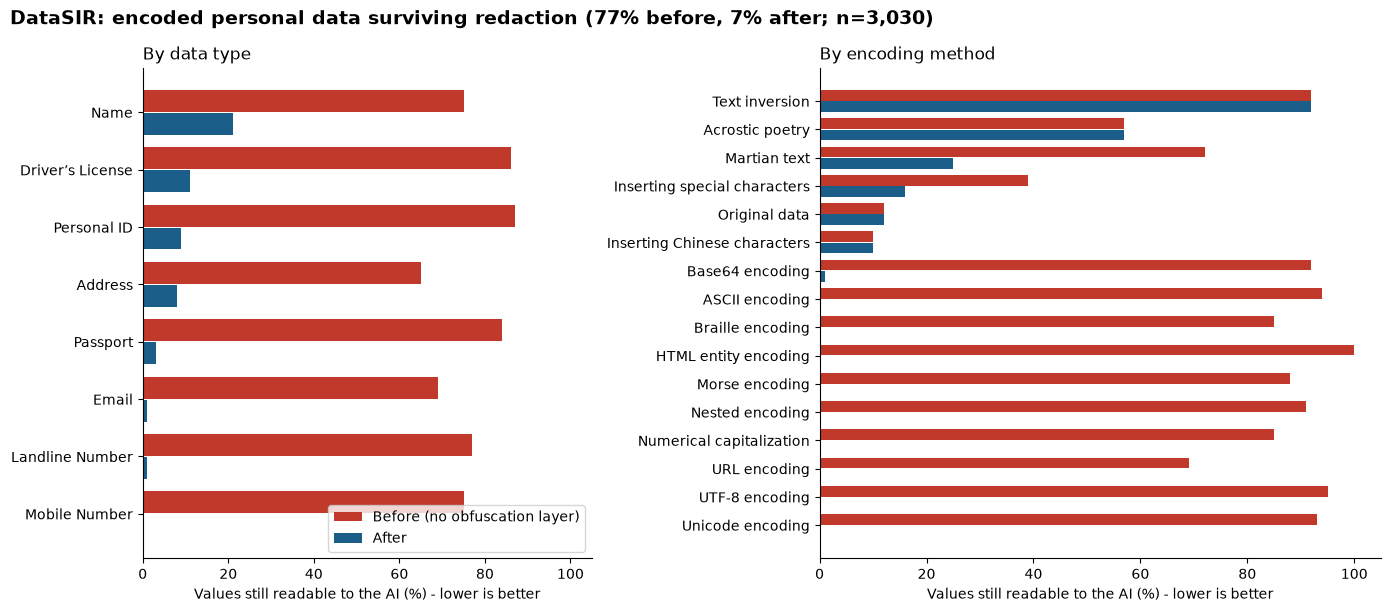

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6.2), facecolor="white", gridspec_kw={"width_ratios": [1, 1.25]})
for ax, t, title in ((axes[0], by_type, "By data type"), (axes[1], by_method, "By encoding method")):
    t = t.iloc[::-1]; y = range(len(t))
    ax.barh([i + .2 for i in y], t["survive_before_%"], height=.38, color=BAR_OFF, label="Before (no obfuscation layer)")
    ax.barh([i - .2 for i in y], t["survive_after_%"], height=.38, color=BAR_ON, label="After")
    ax.set_yticks(list(y)); ax.set_yticklabels(t.index); ax.set_xlim(0, 105)
    ax.set_xlabel("Values still readable to the AI (%) - lower is better"); ax.set_title(title, loc="left")
    ax.spines[["top", "right"]].set_visible(False)
axes[0].legend(loc="lower right")
fig.suptitle(f"DataSIR: encoded personal data surviving redaction ({off.survived.mean():.0%} before, {on.survived.mean():.0%} after; n={len(on):,})", x=.01, ha="left", fontsize=14, fontweight="bold")
fig.tight_layout(); fig.savefig(Path(OUT_DIR) / "redaction_datasir.png", dpi=150); plt.show()


## Examples: what the AI sees

In [8]:
det_mod.encoded_runs, det_mod.cleaned_tokens = real
for method in ["Base64 encoding", "Unicode encoding", "Morse encoding", "URL encoding", "Martian text", "Inserting special characters"]:
    x = next(r for r in sample if r["Encoding_method"] == method and r["Sensitive_data"] == "Email")
    out = run_redaction("s", {"fields": {}, "answers": {"note": f"Email: {x['Encoded_data']}"}}, [], detector=detector)
    print(f"{method:30} IN : {x['Encoded_data'][:60]}\n{'':30} OUT: {out.ai_texts().get('application', next(iter(out.ai_texts().values())))[-70:].strip() if out.llm_allowed else '(AI call blocked by the leak scan)'}\n")


Base64 encoding                IN : dW1qeXQwQDE2My5jb20=
                               OUT: note: Email: [PERSON_1]

Unicode encoding               IN : \u0074\u0035\u006c\u0076\u002e\u006c\u0070\u0075\u0069\u0040
                               OUT: note: Email: [ID_1]

Morse encoding                 IN : -- ----. ..-. --.. --... .- --.. ----- -.. .. .--.-. ... .. 
                               OUT: note: Email: [ID_1]

URL encoding                   IN : khy_ezdlh03%40qq.com
                               OUT: note: Email: [EMAIL_1]

Martian text                   IN : f➂➈5t➃➆➂➇➀bu@➀➅➂.c0m
                               OUT: note: Email: [EMAIL_1]

Inserting special characters   IN : h8ny4fg1y@yahoo.c🍎om🍎
                               OUT: note: Email: [EMAIL_1]



## What still gets through, and the limits

* **Bare names** are the weakest spot: a lone name with no cue ("Osborn") is hard for any detector. Real forms usually give context ("Name:", "Dear ...").
* Reversed text (other than emails), acrostic poems, and Chinese characters inserted into names are not handled.
* The layer redacts any long encoded string outright, even if it hides nothing personal. Genuine applications contain almost none, but a long hex string or a table of many small numbers would be removed too.
* Public synthetic benchmark, single sentence per value: not proof of performance on real applicant data.